In [20]:
from _Aplha_n_methods import Alpha_N_calc as an
from _Geometry_methods import Geometry_helper as gh
from _Prettyplt import PrettyPlot as pp

import openmc
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

import os
pp.makePretty(0.7)

In [21]:
#Geometry
new_geom = True
made_date = '221026'
date = "181026"
hour = 0
nr_steps = 40
timestep_units = 'h'

fuel_name = 'Fuel_CA_2'
blanket_name = 'Blanket_CA'


#Reactor geometry parameters
inner_fuel_r = 50
outer_fuel_r = 60
outer_moderater_r = 80
blanket_or = 100
    
#Control for readtor
inner_moderator_height = 80
    
materials = openmc.Materials.from_xml(f'{date} - materials/{fuel_name}_nr_{hour}_h.xml')
#materials = gh.create_materials(fuel_name)
geom, materials= gh.set_geom_fuel_shell(inner_fuel_r, outer_fuel_r, outer_moderater_r,
                                        with_blanket=True, blanket_or=blanket_or, 
                                        inner_moderator_height=inner_moderator_height, 
                                        materials=materials, fuel_name=fuel_name)

fuel = gh.get_material_by_name(fuel_name,materials)
blanket = gh.get_material_by_name(blanket_name,materials)

fuel.set_density('g/cm3',4.905)
blanket.set_density('g/cm3',4.626)

Materials defined: 
d2o
Air
Blanket_CA
Fuel_CA_2


In [22]:
#Print materials
def print_dep_material(material,threshold = 1e-9):
    total = 0
    new_total = 0
    print(f'\n{material.name}')
    print(f'density: {material.density}')
    #print(material.get_nuclide_atom_densities())
    
    for nuc_name,nuc_amount in material.get_nuclide_densities().items():
        total += nuc_amount.percent
    for nuc_name,nuc_amount in material.get_nuclide_densities().items():
        nuc_percent = nuc_amount.percent
        nuc_percent /= total
        new_total += nuc_percent
        if nuc_percent > threshold:
            print(f'{nuc_name}\t {nuc_percent:.3g}')
    print(f'total: {total:.5g}')
    print(f'new_total: {new_total:.5g}')
def check_fuel_from_ORNL(fuel,threshold = 1e-7):
    print('\n',fuel.name)
    nuclide_lib = {}
    total = 0
    for nuc,dens in fuel.get_nuclide_densities().items():
        symbol,Z,A = an.isolate_atomic_symbol(nuc)
        if symbol != 'F':
            #print(nuc,dens)
            mol = dens.percent
            total += mol
            if symbol in nuclide_lib:
                nuclide_lib[symbol]+=mol
            else:
                nuclide_lib[symbol]=mol
    
    for nuc in nuclide_lib:
        if nuclide_lib[nuc]/total*100 > threshold and nuc != 'F':
            print(f'{nuc}: {nuclide_lib[nuc]/total*100:.10g}')

print_dep_material(fuel)
print_dep_material(blanket)

check_fuel_from_ORNL(fuel)
check_fuel_from_ORNL(blanket)



Fuel_CA_2
density: 4.905
F19	 0.644
Li6	 2.6e-06
Li7	 0.26
U234	 4.3e-05
U235	 0.00481
U236	 2.21e-05
U238	 0.0912
total: 0.08001
new_total: 1

Blanket_CA
density: 4.626
F19	 0.655
Li6	 1.79e-05
Li7	 0.241
Th230	 2.07e-05
Th232	 0.103
total: 0.073034
new_total: 1

 Fuel_CA_2
Li: 72.99999995
Mo: 1.452035312e-07
Np: 1.969647529e-07
U: 26.99999897
Zr: 1.219419399e-07

 Blanket_CA
Li: 70
Th: 29.99999994


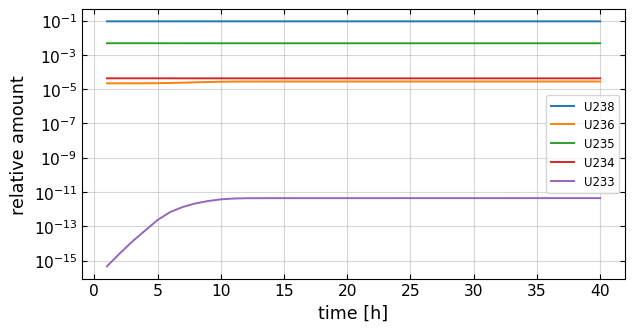

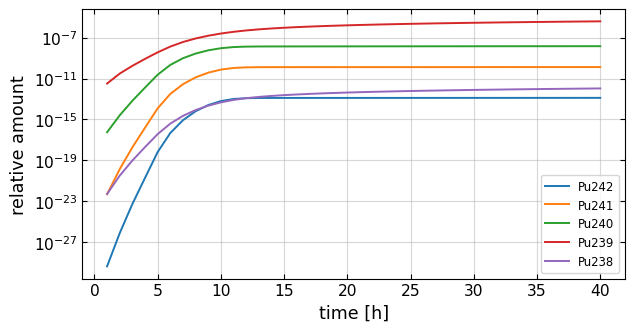

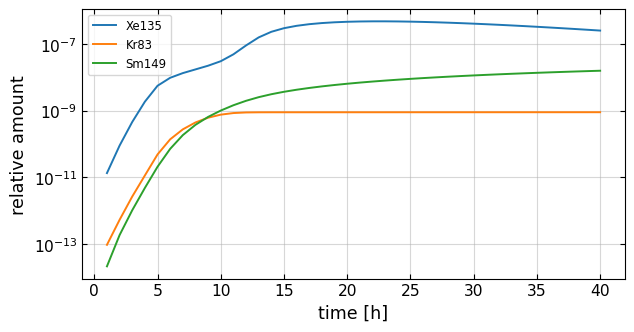

In [23]:
def check_isotopes_from_dep(material,isotopes):
    total = 0
    new_total = 0
    nuclide_lib = {}
    #print(f'\n{material.name}')
    #print(f'density: {material.density}')
    #print(material.get_nuclide_atom_densities())
    
    for nuc_name,nuc_amount in material.get_nuclide_densities().items():
        total += nuc_amount.percent
    for nuc_name,nuc_amount in material.get_nuclide_densities().items():
        nuc_percent = nuc_amount.percent
        nuc_percent /= total
        if nuc_name in isotopes:
            nuclide_lib[nuc_name]=nuc_percent
            #print(f'{nuc_name}: {nuclide_lib[nuc_name]*100:.10g}')
    #print(total)
    return nuclide_lib
def get_isotopes_over_time(isotopes,fuel_name):
    isotopes_over_time = {}
    for isotope in isotopes:
        isotopes_over_time[isotope] = np.zeros(nr_steps)
        for hour in range(nr_steps):
            mats = openmc.Materials.from_xml(f'{date} - materials/{fuel_name}_nr_{hour}_h.xml')
            mat = gh.get_material_by_name(fuel_name,mats)
            
            isotope_lib = check_isotopes_from_dep(mat,isotope)
            
            isotopes_over_time[isotope][hour]= isotope_lib[isotope]
        

    return isotopes_over_time

#check_isotopes_from_dep(fuel,['Xe135','U235'])
fuel_U = ['U238','U236','U235','U234','U233']
fuel_Pu = ['Pu242','Pu241','Pu240','Pu239','Pu238']
poisons = ['Xe135','Kr83','Sm149']

for isotopes,name in zip([fuel_U,fuel_Pu,poisons],['fuel_U','fuel_Pu','poisons']):


    isotopes_over_time = get_isotopes_over_time(isotopes,fuel_name)
    
    fig,ax = plt.subplots()
    ax
    for isotope in isotopes:
        ax.plot(np.array(range(nr_steps))+1,isotopes_over_time[isotope],label = isotope)
    ax.set_xlabel('time [h]')
    ax.set_ylabel('relative amount')
    ax.semilogy()
    ax.legend()
    ax.grid(alpha=0.5)
    
    pp.savefig(f'{made_date}/{name}_{date}')

In [ ]:
#Alpha-n from material
def shell_vol_calc(geom_or,geom_ir):
    volume=4/3*np.pi*(geom_or**3-geom_ir**3)
    return volume

def set_source(material,innr_r,outer_r):
    print(f'\n\n {material.name}')
    n_intensities,n_energies,n_per_s_per_kg = an.neutron_spectra_from_material(material,E_min=1e4,
                                                                               nr_points=1000,nr_energies=1000,
                                                                               new_file=True)
    
    n_intensities = np.clip(n_intensities,0,None)
    energy = openmc.stats.Tabular(n_energies, n_intensities)
    
    ax.plot(n_energies,n_intensities,label=material.name)
    
    material_vol = shell_vol_calc(outer_fuel_r,inner_fuel_r)
    material_mass = material.density*material_vol/1000
    total_n_per_s = n_per_s_per_kg*material_mass

    print(f'total_n_per_s: {total_n_per_s:.5g} for {material.name}')

    return openmc.IndependentSource(space=fuel_space, energy=energy,particle='neutron', strength=total_n_per_s)

inner_fuel_radius = geom.get_surfaces_by_name('fuel_inner')[0].bounding_box('-')[1][0]
outer_fuel_radius = geom.get_surfaces_by_name('fuel_outer')[0].bounding_box('-')[1][0]

inner_blanket_radius = geom.get_surfaces_by_name('blanket_inner')[0].bounding_box('-')[1][0]
outer_blanket_radius = geom.get_surfaces_by_name('blanket_outer')[0].bounding_box('-')[1][0]

fuel_space = openmc.stats.spherical_uniform(r_outer=outer_fuel_radius,r_inner=inner_fuel_radius)
blanket_space = openmc.stats.spherical_uniform(r_outer=outer_blanket_radius,r_inner=inner_blanket_radius)

fig,ax =plt.subplots()

ax.set_xlabel('Energy [eV]')
ax.set_ylabel(r'$\frac{n}{kg\cdot s}$')

fuel_src = set_source(fuel,inner_fuel_radius,outer_fuel_radius)
blanket_src = set_source(blanket,inner_blanket_radius,outer_blanket_radius)


ax.legend()








 Fuel_CA_2
Writing SRIM file after 47 threshold tries
len target elements 100, #elements 100
Waiting for SRModule to produce output...
Waiting for SRModule to produce output...


In [10]:
#Settings
settings = openmc.Settings()
settings.run_mode = 'eigenvalue'
settings.source =  [fuel_src,blanket_src]   # evt. + SF-kilde som separat source
settings.batches = 100
settings.inactive = 10
settings.particles = 10000 # is changed later

#Fixing Li6 at 900 K doesn't have a cross section 
settings.temperature = {
    'method': 'nearest',
    'tolerance': 1000}

model_eigen = openmc.Model(geometry=geom, materials=materials, settings=settings)



In [11]:
#Finding k_eff
#model_eigen.run()

In [12]:
keffs = np.zeros(nr_steps)
keffs_std = np.zeros(nr_steps)
for step in range(nr_steps):
    openmc.reset_auto_ids()
    os.system('rm s*h5')
    os.system('rm p*h5')
    os.system("rm model.xml")
    os.system("rm summary.h5")
    materials = openmc.Materials.from_xml(f'{date} - materials/{fuel_name}_nr_{step}_h.xml')
    #materials = gh.create_materials(fuel_name)
    geom, materials= gh.set_geom_fuel_shell(inner_fuel_r, outer_fuel_r, outer_moderater_r,
                                            with_blanket=True, blanket_or=blanket_or, 
                                            inner_moderator_height=inner_moderator_height, 
                                            materials=materials, fuel_name=fuel_name)
    
    fuel = gh.get_material_by_name(fuel_name,materials)
    blanket = gh.get_material_by_name(blanket_name,materials)
    
    model_eigen.geometry = geom
    model_eigen.materials = materials
    model_eigen.run()
    with openmc.StatePoint(f'statepoint.{settings.batches}.h5') as sp:
        keff = sp.keff
    
    keffs[step] = keff.nominal_value
    keffs_std[step] = keff.std_dev
    
    os.system(f'statepoint.{settings.batches}.h5')
    print(keffs[step])

#Saving results
data_to_file = np.column_stack((keffs,keffs_std))
np.savetxt(f'data/eigenvalue_{date}_time_{nr_steps}_{timestep_units}.csv',data_to_file,delimiter=",",
           header='keffs,keffs_std')

rm: cannot remove 'p*h5': No such file or directory
rm: cannot remove 'summary.h5': No such file or directory


Materials defined: 
d2o
Air
Blanket_CA
Fuel_CA_2
                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 #######################     %%%%%%%

sh: 1: statepoint.100.h5: not found
rm: cannot remove 'p*h5': No such file or directory
rm: cannot remove 'summary.h5': No such file or directory


0.9953500998486884
Materials defined: 
d2o
Air
Blanket_CA
Fuel_CA_2
                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 ################

KeyboardInterrupt: 

In [9]:
print(keffs)

[0.9962788  0.99547351 0.99414197 0.99517889 1.00062167 0.99437839
 0.99845887 0.99870777 0.99639376 1.00062484 1.00075646 0.99831076
 0.9992587  0.99255816 1.00015031 0.99264404 0.99885144 0.9919664
 0.99255229 0.99417748 0.9988575  0.99529623 0.99577737 0.99146589]
